In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
t = np.linspace(0, 10/60, 256*10)
w_fund = 2*np.pi*60
v =  20*np.sin(1*w_fund*t) + 10*np.sin(3*w_fund*t) + 7*np.sin(5*w_fund*t) + 5*np.cos(7*w_fund*t)

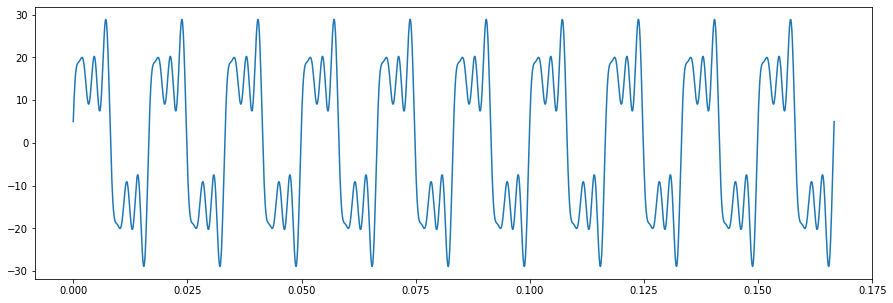

In [ ]:
plt.figure(figsize=(15,5))
plt.plot(t,v)

plt.show()

Termos do cosseno

$${{a}_{k}}=\frac{\int_{{}}^{{}}{f\left( x \right)\cos \left( kx \right)dx}}{\int_{{}}^{{}}{\cos \left( kx \right)\cos \left( kx \right)dx}}$$

In [ ]:
nn = 10
a = np.zeros(nn)
b = np.zeros(nn)
for k in range(nn):
    # cosseno
    num = np.trapz(v * np.cos(k*w_fund*t), t)
    den = np.trapz(np.cos(k*w_fund*t)*np.cos(k*w_fund*t), t)
    if den != 0:
        a[k] = num/den
    # seno
    num = np.trapz(v * np.sin(k*w_fund*t), t)
    den = np.trapz(np.sin(k*w_fund*t)*np.sin(k*w_fund*t), t)
    if den != 0:
        b[k] = num/den

a = np.round(a, 3)
b = np.round(b, 3)

In [ ]:
b

array([ 0., 20., -0., 10.,  0.,  7., -0., -0.,  0., -0.])

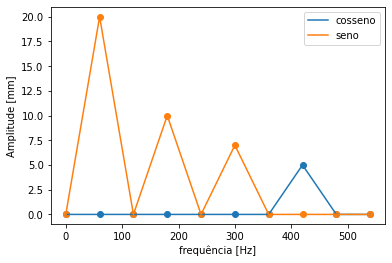

In [ ]:
freqs = w_fund*np.arange(nn)/(2*np.pi)
plt.plot(freqs, a, label='cosseno')
plt.plot(freqs, b, label='seno')
plt.scatter(freqs, a)
plt.scatter(freqs, b)
plt.legend()
plt.xlabel("frequência [Hz]")
plt.ylabel("Amplitude [mm]")
plt.show()

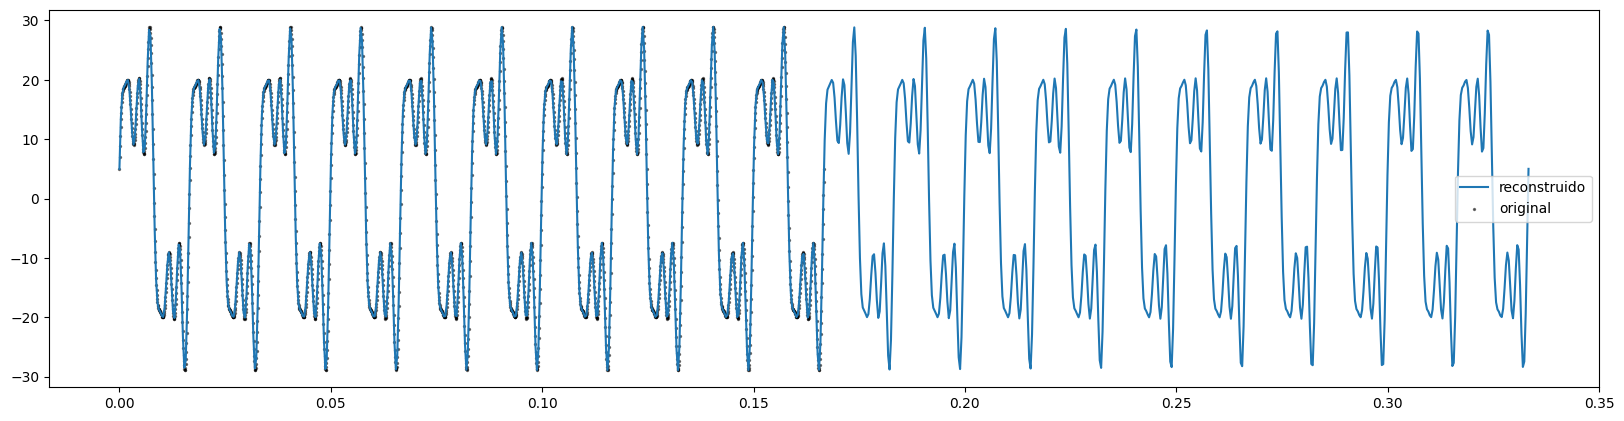

In [ ]:
tt = np.linspace(0, 20/60, 1000)
rec = np.zeros(len(tt))
fig, ax = plt.subplots(figsize=(20,5))
for ii in range(nn):
    y = a[ii]*np.cos(ii*w_fund*tt) + b[ii]*np.sin(ii*w_fund*tt)
    # ax.plot(tt, y, label=str(ii))
    rec = rec + y
ax.plot(tt, rec, label='reconstruido')
ax.scatter(t, v, label='original', alpha=0.5, s=2, color='black')
ax.legend()
fig.dpi = 100

fig.show()

In [ ]:
b

array([ 0., 20., -0., 10.,  0.,  7., -0., -0.,  0., -0.])

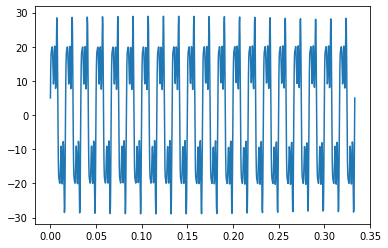

In [ ]:
plt.plot(tt, rec)